# 03 · Fraud Prediction, Experimental Validation & Model Diagnostics

**Credit Card Fraud Analytics & Investigation Optimization**  
*Research notebook · leakage prevention, training-only selection, real holdout predictions, error audits, uncertainty and business-relevant model performance*

> **Research question:** Can a training-selected model rank and identify fraud on unseen historical transactions, how does validation design affect the evidence, and what do the observed errors imply for investigation decisions?

**Evidence contract:** This notebook is **read-only** over `src.ml_models` and `src.model_evaluation` artifacts. It never trains a model, modifies a saved artifact, retunes a threshold, resamples the holdout, or optimizes a downstream investigation policy. *All displayed transaction-level predictions are real saved model outputs.*

**Primary analysis:** complete **chronological** experiment. **Secondary sensitivity:** complete **stratified random** experiment when its report exists; preliminary smoke runs are explicitly excluded.

**Navigation** — A: Data and validation (sections 1–4) · B: Training selection (5–7) · C: Holdout predictions (8–11) · D: Reliability and decision handoff (12–13).

**Population boundary:** Notebooks 01–02 used the original duplicate-retained dataset (284,807 rows); ML uses an independently documented *deduplicated* dataset (283,726 rows). Do not compare counts across these populations without noting the distinction.

## A · Experimental design and provenance
### 1 · Research questions and success criteria

1. **Detection:** Do held-out scores meaningfully rank rare fraud cases above legitimate transactions? Measure **average precision (AP)** against the corresponding holdout prevalence; supplement with ROC-AUC.
2. **Model selection:** Which of nine predefined model/imbalance combinations wins on **training-only pooled out-of-fold AP**?
3. **Classification:** What precision, recall, F1 and review volume result from the **training-only F1-selected threshold**?
4. **Value:** How much *recorded fraudulent transaction amount* is flagged versus missed? This is not verified loss or prevented value.
5. **Reliability:** How sensitive are descriptive findings to random versus chronological evaluation, errors, calibration and elapsed-time variation?

**Terminology:** The project calls sklearn's `average_precision_score` “PR-AUC”; the notebook states **AP** explicitly, because interpolated trapezoidal PR area is not the same statistic.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import display, Markdown, Image
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, brier_score_loss, precision_recall_curve, roc_curve)

pd.set_option('display.max_columns', 20)
NAVY, TEAL, GOLD, RED, GREY = '#142c45', '#088b91', '#c58a37', '#ce4d59', '#61758a'
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150, 'font.size': 10, 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor':'white'})

def find_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate/'reports/tables/ml').is_dir():
            return candidate
    raise FileNotFoundError('No reports/tables/ml folder found. Run from the project root or notebooks/; '
                            'generate existing src.ml_models reports if absent.')
ROOT=find_root()
ML=ROOT/'reports/tables/ml'
FIG=ROOT/'reports/figures/ml'

def load_csv(base, filename, required):
    p=base/filename
    if not p.is_file(): raise FileNotFoundError(f'Missing required artifact: {p.relative_to(ROOT)}')
    df=pd.read_csv(p)
    missing=set(required)-set(df.columns)
    if missing: raise ValueError(f'{p.name} missing required columns: {sorted(missing)}')
    if df.empty: raise ValueError(f'{p.name} is empty')
    return df

def show(df, columns=None, formats=None):
    view=df[columns].copy() if columns is not None else df.copy()
    display(view.style.format(formats or {}, na_rep='—'))

def plot_done(fig):
    fig.tight_layout()
    plt.show()
print('Project root:',ROOT)
print('Execution mode: READ ONLY | no fitting, no threshold selection on holdout')

Project root: E:\DataAnalytics\Projects\Credit_Card_Fraud_Analytics
Execution mode: READ ONLY | no fitting, no threshold selection on holdout


### 2 · Locate the genuine full ML experiments

We classify a run as **full** only when its `run_metadata.json` declares **three model families and three imbalance strategies** and its saved candidate table has all nine model–strategy pairs. A one-model smoke test may be useful for debugging, but **must never enter headline comparisons**. The chronological full run is mandatory; a random full run is optional because a developer might transfer the notebook before copying that report family.

In [2]:
def discover_full_runs():
    complete=[]; excluded=[]
    for file in sorted(ML.glob('*/run_metadata.json')):
        folder=file.parent
        try:
            meta=json.loads(file.read_text(encoding='utf-8'))
            sel=pd.read_csv(folder/'cv_model_selection.csv')
            good=(len(meta.get('model_choices', []))==3 and len(meta.get('strategies', []))==3
                  and len(sel)==9 and {'key','cv_oof_ap'}.issubset(sel.columns) and sel.key.nunique()==9
                  and (folder/'holdout_metrics.csv').is_file() and (folder/'holdout_predictions.csv').is_file())
            if good:complete.append((folder.name,meta))
            else:excluded.append((folder.name,'partial/smoke/incomplete'))
        except (OSError,ValueError,KeyError) as exc:
            excluded.append((folder.name,str(exc)))
    return complete,excluded

complete,excluded=discover_full_runs()
chrono=[(name,meta) for name,meta in complete if meta.get('split')=='chronological']
random_runs=[(name,meta) for name,meta in complete if meta.get('split')=='random']
if not chrono:raise FileNotFoundError('No *full* chronological ML run found under reports/tables/ml/.')
CHRONO,cm=chrono[0]
RANDOM,rm=random_runs[0] if random_runs else (None,None)
assert cm.get('selection')=='highest pooled training out-of-fold average precision'
assert cm.get('threshold_objective')=='f1'
print('Primary run:',CHRONO,'| trained winner:',cm['selected_model'])
print('Secondary full random run:', RANDOM or 'not available; comparison will be skipped')
print('Partial/smoke runs excluded:',[name for name,_ in excluded])

Primary run: chronological_dedup_withTime_463fcded | trained winner: XGBoost__SMOTE
Secondary full random run: random_dedup_withTime_463fcded
Partial/smoke runs excluded: ['random_dedup_withTime_ee769471']


### 3 · Model population, features and provenance

The modeling pipeline removes exact duplicates **before splitting**. The chronology is deterministic (by `Time` and stable original-row ordering); the pipeline enforces separation at a boundary timestamp. It uses the 28 anonymized `V` features, `Time`, and `Amount` as recorded in metadata. Neither `Class` nor `original_row` may be a model input. The original-row index is only an audit identifier.

The split fraction is a target, not necessarily the exact realized fraction: the chronological pipeline can exclude boundary rows to avoid timestamp overlap. We verify the partition counts against the metadata rather than inventing a fixed boundary count.

In [3]:
quality=cm['data_quality']
assert quality['input_rows']==284807 and quality['exact_duplicate_rows']==1081
assert quality['duplicate_handling']=='drop_before_split'
assert cm['train_rows']+cm['test_rows']<=quality['input_rows']-quality['exact_duplicate_rows']
features=cm['features']
assert len(features)==30 and len(set(features))==30 and 'Class' not in features and 'original_row' not in features
assert 'Time' in features and 'Amount' in features and len([x for x in features if x.startswith('V')])==28
population=pd.DataFrame([
 {'Population':'Original duplicate-retained','Transactions':quality['input_rows']},
 {'Population':'Unique after exact deduplication','Transactions':quality['input_rows']-quality['exact_duplicate_rows']},
 {'Population':'Chronological training','Transactions':cm['train_rows']},
 {'Population':'Locked chronological holdout','Transactions':cm['test_rows']},
 {'Population':'Not assigned at split boundary','Transactions':quality['input_rows']-quality['exact_duplicate_rows']-cm['train_rows']-cm['test_rows']},
])
show(population,formats={'Transactions':'{:,.0f}'})
print('Feature inventory:',', '.join(features))
print('Raw file fingerprint recorded by pipeline:',cm['raw_csv_sha256'][:16]+'…')
print('Selected model:',cm['selected_model'],'| threshold:',format(cm['selected_threshold'],'.9f'))

,Population,Transactions
0,Original duplicate-retained,"284,807"
1,Unique after exact deduplication,"283,726"
2,Chronological training,"198,607"
3,Locked chronological holdout,"85,118"
4,Not assigned at split boundary,1


Feature inventory: V1, V2, V3, V4, V5, V6, V7, V8, V9, V10, V11, V12, V13, V14, V15, V16, V17, V18, V19, V20, V21, V22, V23, V24, V25, V26, V27, V28, Time, Amount
Raw file fingerprint recorded by pipeline: 76274b691b16a6c4…
Selected model: XGBoost__SMOTE | threshold: 0.715498447


### 4 · Leakage-prevention architecture

**Random experiment:** stratified random train/test split followed by stratified folds **inside training only**. This tests performance on a random, exchangeable-style partition and may be optimistic for time-sensitive fraud behavior.

**Chronological experiment:** time-ordered holdout with **three expanding-window `TimeSeriesSplit` folds** inside training. Earlier observations in expanding CV have *no* out-of-fold predictions, so the pooled OOF sample is smaller than the training partition.

**Within each CV fold:** scaling and/or SMOTE are fitted only on its training observations. Class weighting is fitted from the training fold. Neither sampler nor scaler is fitted on holdout data.

**Decision order:** training-only candidate CV AP → winning candidate → training-OOF threshold optimization (F1) → fit the selected configuration on training → *one locked holdout evaluation*. No holdout-based retraining, policy selection, or probability recalibration.

In [4]:
assert cm['split']=='chronological' and cm['cv_folds']==3 and 'TimeSeriesSplit' in cm['cv_policy']
architecture=pd.DataFrame([
 ('1. Split','Train / untouched test','Dataset; preserve holdout boundary'),
 ('2. Fit CV folds','Preprocessing and sampling inside each training fold','Only fold-training features and labels'),
 ('3. Rank candidates','Highest pooled training OOF average precision','Training OOF labels and scores'),
 ('4. Choose threshold','Maximize training OOF F1','Winner training OOF only'),
 ('5. Final model fit','Train complete selected configuration','Training partition only'),
 ('6. Locked test report','Evaluate once','Scores and labels; no selection'),
],columns=['Stage','Action','Permitted evidence'])
show(architecture)

,Stage,Action,Permitted evidence
0,1. Split,Train / untouched test,Dataset; preserve holdout boundary
1,2. Fit CV folds,Preprocessing and sampling inside each training fold,Only fold-training features and labels
2,3. Rank candidates,Highest pooled training OOF average precision,Training OOF labels and scores
3,4. Choose threshold,Maximize training OOF F1,Winner training OOF only
4,5. Final model fit,Train complete selected configuration,Training partition only
5,6. Locked test report,Evaluate once,Scores and labels; no selection


## B · Training-only model and threshold selection
### 5 · All nine candidate configurations

The candidate grid combines **Logistic Regression, Random Forest and XGBoost** with **baseline, SMOTE and class weighting**. Selection is based on *pooled training OOF AP*, not the holdout F1 score or assumed financial savings. This is a deliberately bounded candidate search, **not** a hyperparameter optimization study.

In [5]:
folder=ML/CHRONO
cv=load_csv(folder,'cv_model_selection.csv',{'key','model','strategy','cv_oof_ap','cv_folds_mean_ap','cv_folds_std_ap','oof_rows','threshold','cv_selected_f1'})
fold=load_csv(folder,'cv_fold_results.csv',{'key','fold','train_rows','validation_rows','train_fraud','validation_fraud','fold_ap'})
assert len(cv)==9 and len(fold)==27 and cv.key.nunique()==9
assert set(fold.key)==set(cv.key)
cv=cv.sort_values('cv_oof_ap',ascending=False).reset_index(drop=True)
assert cv.key.iloc[0]==cm['selected_model']
assert np.isclose(cv.threshold.iloc[0],cm['selected_threshold'],rtol=0,atol=1e-8)
show(cv[['key','cv_oof_ap','cv_folds_mean_ap','cv_folds_std_ap','oof_rows','threshold','cv_selected_f1']],
     formats={x:'{:.4f}' for x in ['cv_oof_ap','cv_folds_mean_ap','cv_folds_std_ap','cv_selected_f1']})

,key,cv_oof_ap,cv_folds_mean_ap,cv_folds_std_ap,oof_rows,threshold,cv_selected_f1
0,XGBoost__SMOTE,0.7641,0.7630,0.0616,148953,0.715498,0.8186
1,RandomForest__SMOTE,0.7593,0.7521,0.0600,148953,0.533333,0.8200
2,XGBoost__baseline,0.7543,0.7547,0.0694,148953,0.661415,0.8010
3,XGBoost__class_weight,0.7506,0.7461,0.0634,148953,0.655467,0.8087
4,RandomForest__baseline,0.7495,0.7542,0.0414,148953,0.541667,0.8081
5,RandomForest__class_weight,0.7463,0.7398,0.0643,148953,0.225000,0.8150
6,LogisticRegression__SMOTE,0.7046,0.7263,0.0970,148953,0.989301,0.7281
7,LogisticRegression__class_weight,0.6653,0.6817,0.1302,148953,0.999665,0.6636
8,LogisticRegression__baseline,0.5248,0.5369,0.1521,148953,0.201725,0.5798


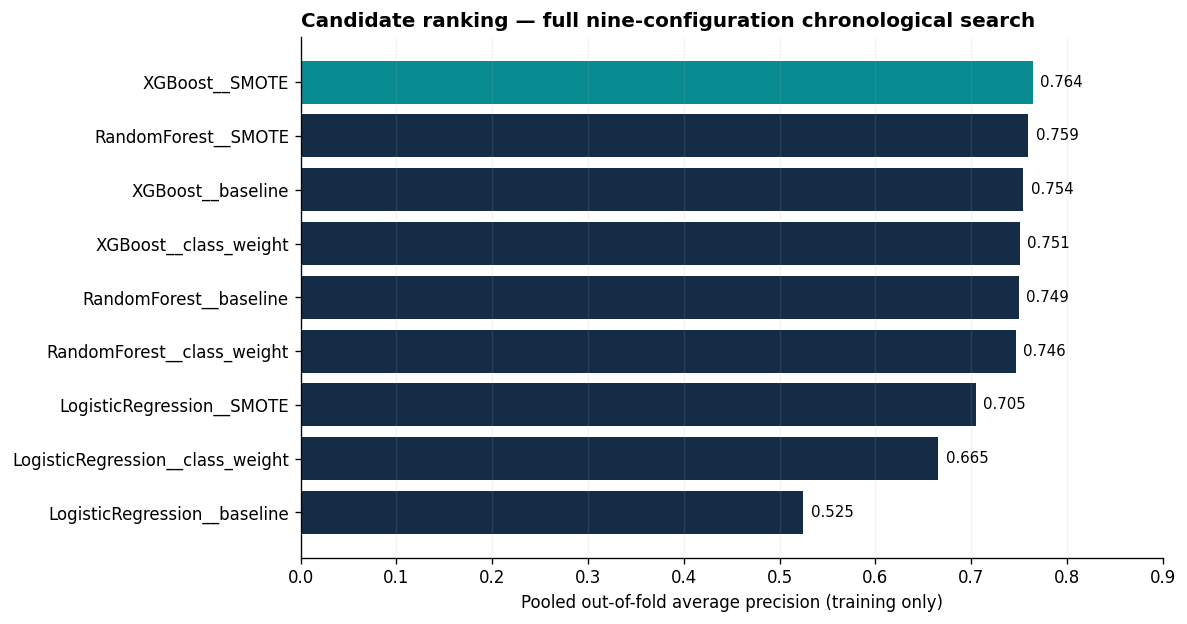

In [6]:
fig,ax=plt.subplots(figsize=(10,5.3))
r=cv.iloc[::-1];bars=ax.barh(r.key,r.cv_oof_ap,color=[TEAL if key==cm['selected_model'] else NAVY for key in r.key]);
for bar,value in zip(bars,r.cv_oof_ap):ax.text(value+.008,bar.get_y()+bar.get_height()/2,f'{value:.3f}',va='center',fontsize=9)
ax.set_xlim(0,max(.9,float(cv.cv_oof_ap.max())+.08));ax.set_xlabel('Pooled out-of-fold average precision (training only)')
ax.set_title('Candidate ranking — full nine-configuration chronological search',loc='left',fontweight='bold');ax.grid(axis='x',alpha=.14)
plot_done(fig)

**Interpretation:** The leading pooled AP wins *by the selection rule*, even when another candidate has stronger thresholded F1, a better individual fold, or a higher hypothetical scenario number. Fold variability is descriptive evidence of validation sensitivity, not a confidence interval.

### 6 · Expanding-window folds and honest OOF scope

Do not imply that every training row received an OOF score. Earlier observations serve as initial expanding-window training history, not as validation points.

In [7]:
selected_folds=fold[fold.key.eq(cm['selected_model'])].sort_values('fold')
assert len(selected_folds)==3
assert int(selected_folds.validation_rows.sum())==int(cv.loc[cv.key.eq(cm['selected_model']),'oof_rows'].iloc[0])
assert int(selected_folds.validation_rows.sum())<int(cm['train_rows'])
show(selected_folds,formats={'fold_ap':'{:.4f}','validation_rows':'{:,.0f}','train_rows':'{:,.0f}'})
print(f"Training rows: {cm['train_rows']:,} | pooled OOF rows: {selected_folds.validation_rows.sum():,} "
      f"| no OOF prediction: {cm['train_rows']-selected_folds.validation_rows.sum():,}")

,key,fold,train_rows,validation_rows,train_fraud,validation_fraud,fold_ap
21,XGBoost__SMOTE,1,"49,652","49,651",148,75,0.7883
22,XGBoost__SMOTE,2,"99,305","49,651",223,56,0.6929
23,XGBoost__SMOTE,3,"148,956","49,651",279,87,0.8080


Training rows: 198,607 | pooled OOF rows: 148,953 | no OOF prediction: 49,654


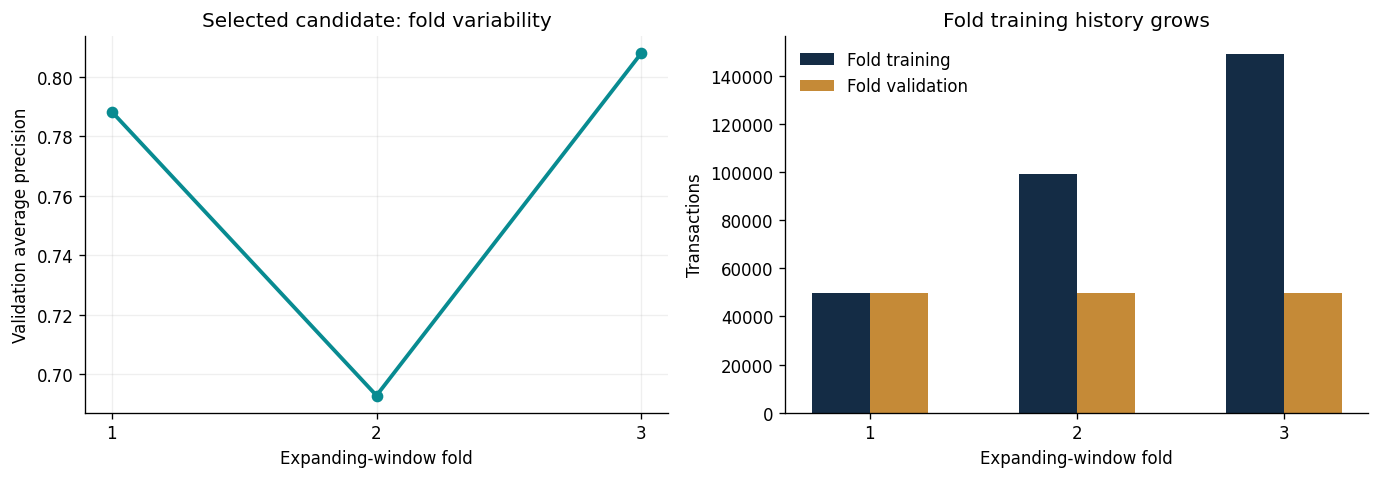

In [8]:
fig,axes=plt.subplots(1,2,figsize=(11.6,4.1))
axes[0].plot(selected_folds.fold,selected_folds.fold_ap,marker='o',color=TEAL,linewidth=2.3)
axes[0].set(xlabel='Expanding-window fold',ylabel='Validation average precision',title='Selected candidate: fold variability')
axes[0].set_xticks([1,2,3]);axes[0].grid(alpha=.2)
axes[1].bar(selected_folds.fold-.14,selected_folds.train_rows,width=.28,label='Fold training',color=NAVY)
axes[1].bar(selected_folds.fold+.14,selected_folds.validation_rows,width=.28,label='Fold validation',color=GOLD)
axes[1].set(xlabel='Expanding-window fold',ylabel='Transactions',title='Fold training history grows')
axes[1].set_xticks([1,2,3]);axes[1].legend(frameon=False)
plot_done(fig)

### 7 · The saved training-selected threshold

The operating threshold was chosen by maximizing **training OOF F1 for the CV-selected winner**. The notebook deliberately does not sweep thresholds on holdout predictions. A ranking score's absolute value need not be a calibrated fraud probability.

In [9]:
winner=cv.iloc[0]
selection=pd.DataFrame([{'Selected configuration':cm['selected_model'],'Selection metric':'Pooled training OOF AP',
                         'Training OOF AP':winner.cv_oof_ap,'Training OOF rows':int(winner.oof_rows),
                         'Threshold criterion':'Training OOF F1 maximum','Threshold':float(cm['selected_threshold']),
                         'Selected OOF F1':float(winner.cv_selected_f1)}])
show(selection,formats={'Training OOF AP':'{:.4f}','Threshold':'{:.6f}','Selected OOF F1':'{:.4f}'})
# Training threshold curve is not required by older complete releases; show it if present.
p=folder/'training_threshold_curve.csv'
if p.is_file():
    curve=pd.read_csv(p)
    print('Saved training threshold-curve columns:',list(curve.columns))
    display(curve.head(3))
else:
    print('No saved training_threshold_curve.csv in this run. Selection provenance above remains available from metadata and CV report.')

,Selected configuration,Selection metric,Training OOF AP,Training OOF rows,Threshold criterion,Threshold,Selected OOF F1
0,XGBoost__SMOTE,Pooled training OOF AP,0.7641,148953,Training OOF F1 maximum,0.715498,0.8186


Saved training threshold-curve columns: ['threshold', 'alerts', 'tp', 'fp', 'fn', 'precision', 'recall', 'f1', 'fraud_value_recall', 'scenario_net_value']


,threshold,alerts,tp,fp,fn,precision,recall,f1,fraud_value_recall,scenario_net_value
0,0.999957,0,0,0,218,0.0,0.000000,0.000000,0.000000,0.00
1,0.999957,1,1,0,217,1.0,0.004587,0.009132,0.010099,142.45
2,0.999936,2,2,0,216,1.0,0.009174,0.018182,0.015354,214.18


## C · Actual locked-holdout predictions
### 8 · Load, verify and classify the **real** saved predictions

The saved `holdout_predictions.csv` is the authoritative transaction-level output of the trained pipeline. Columns: `original_row`, `Time`, `Amount`, `Class`, `score`, `predicted_fraud`, `error_type`. `original_row` is an audit row index, **not a customer identifier**. We will independently check `score ≥ threshold`, confusion counts, score range and label semantics. No demonstrations use fabricated predictions.

In [10]:
pred=load_csv(folder,'holdout_predictions.csv',{'original_row','Time','Amount','Class','score','predicted_fraud','error_type'})
metric=load_csv(folder,'holdout_metrics.csv',{'tn','fp','fn','tp','pr_auc','roc_auc','precision','recall','f1','threshold',
               'brier_score','flagged_fraud_amount','missed_fraud_amount','fraud_value_recall','alerts','test_fraud',
               'selected_model','split','train_rows','test_rows'}).iloc[0]
assert len(pred)==cm['test_rows']==int(metric.test_rows)
assert pred.original_row.is_unique
assert set(pred.Class.unique()).issubset({0,1}) and set(pred.predicted_fraud.unique()).issubset({0,1})
assert pred.score.notna().all() and pred.score.between(0,1).all()
assert pred.Amount.notna().all() and pred.Amount.ge(0).all()
assert np.isclose(metric.threshold,cm['selected_threshold'],atol=1e-7)
assert metric.selected_model==cm['selected_model'] and metric.split=='chronological'
assert (pred.predicted_fraud.to_numpy()==(pred.score.to_numpy()>=float(cm['selected_threshold'])).astype(int)).all()
expected=np.select([(pred.Class.eq(1)&pred.predicted_fraud.eq(1)),(pred.Class.eq(0)&pred.predicted_fraud.eq(1)),
                    (pred.Class.eq(1)&pred.predicted_fraud.eq(0))],['TP','FP','FN'],default='TN')
assert (pred.error_type.to_numpy()==expected).all()
assert int(pred.Class.sum())==int(metric.test_fraud)
print(f'PASS: {len(pred):,} saved predictions, no duplicate original-row IDs, scores/labels/threshold/outcomes reconcile')
print('Model:',metric.selected_model,'| threshold:',f'{metric.threshold:.6f}')

PASS: 85,118 saved predictions, no duplicate original-row IDs, scores/labels/threshold/outcomes reconcile
Model: XGBoost__SMOTE | threshold: 0.715498


In [11]:
y=pred.Class.astype(int).to_numpy();s=pred.score.to_numpy();yhat=pred.predicted_fraud.astype(int).to_numpy()
tn,fp,fn,tp=confusion_matrix(y,yhat,labels=[0,1]).ravel()
assert (tn,fp,fn,tp)==(int(metric.tn),int(metric.fp),int(metric.fn),int(metric.tp))
calculated={'Precision':precision_score(y,yhat,zero_division=0),'Recall':recall_score(y,yhat,zero_division=0),
            'F1':f1_score(y,yhat,zero_division=0),'Average precision':average_precision_score(y,s),
            'ROC-AUC':roc_auc_score(y,s),'Brier score':brier_score_loss(y,s)}
fields={'Precision':'precision','Recall':'recall','F1':'f1','Average precision':'pr_auc','ROC-AUC':'roc_auc','Brier score':'brier_score'}
for label,val in calculated.items():assert np.isclose(val,float(metric[fields[label]]),atol=1e-7),label
fraud_total=pred.loc[pred.Class.eq(1),'Amount'].sum()
flagged=pred.loc[pred.error_type.eq('TP'),'Amount'].sum()
missed=pred.loc[pred.error_type.eq('FN'),'Amount'].sum()
legitimate_flagged=pred.loc[pred.error_type.eq('FP'),'Amount'].sum()
value_recall=flagged/fraud_total if fraud_total else np.nan
assert np.isclose(flagged,metric.flagged_fraud_amount,atol=.011)
assert np.isclose(missed,metric.missed_fraud_amount,atol=.011)
assert np.isclose(value_recall,metric.fraud_value_recall,atol=1e-7)
assert tp+fp==int(metric.alerts)
audit=pd.DataFrame([{'Measure':k,'Recomputed':v,'Saved result':metric[fields[k]]} for k,v in calculated.items()])
show(audit,formats={'Recomputed':'{:.6f}','Saved result':'{:.6f}'})
print('PASS — all six predictive metrics and fraud-value accounting independently recomputed')

,Measure,Recomputed,Saved result
0,Precision,0.829787,0.829787
1,Recall,0.728972,0.728972
2,F1,0.776119,0.776119
3,Average precision,0.783137,0.783137
4,ROC-AUC,0.982964,0.982964
5,Brier score,0.000627,0.000627


PASS — all six predictive metrics and fraud-value accounting independently recomputed


### 9 · Classification versus ranking performance

**Precision** measures fraud yield among alerts; **recall** measures covered fraud cases; **F1** balances the two *at the training-selected threshold*. **Average precision** evaluates ranking across thresholds. The correct no-skill AP context is **holdout prevalence**, not 0.5. ROC-AUC can look impressive in very imbalanced settings while hiding alert burden.

In [12]:
prevalence=y.mean();alerts=int(yhat.sum())
summary=pd.DataFrame([
 ('Holdout observations',len(y)),('Fraud cases',int(y.sum())),('Fraud prevalence (%)',100*prevalence),
 ('Average precision',calculated['Average precision']),('No-skill AP reference',prevalence),
 ('ROC-AUC',calculated['ROC-AUC']),('Precision (%)',100*calculated['Precision']),
 ('Case recall (%)',100*calculated['Recall']),('F1',calculated['F1']),
 ('Alert count',alerts),('Alerts per 1,000 transactions',1000*alerts/len(y)),
 ('Specificity (%)',100*tn/(tn+fp))],columns=['Measure','Value'])
show(summary,formats={'Value':'{:,.5f}'})
print(f'Observed false-alert count: {fp:,}; fraud cases missed: {fn:,}. These are historical outcomes, not deployed alerts.')

,Measure,Value
0,Holdout observations,"85,118.00000"
1,Fraud cases,107.00000
2,Fraud prevalence (%),0.12571
3,Average precision,0.78314
4,No-skill AP reference,0.00126
5,ROC-AUC,0.98296
6,Precision (%),82.97872
7,Case recall (%),72.89720
8,F1,0.77612
9,Alert count,94.00000


Observed false-alert count: 16; fraud cases missed: 29. These are historical outcomes, not deployed alerts.


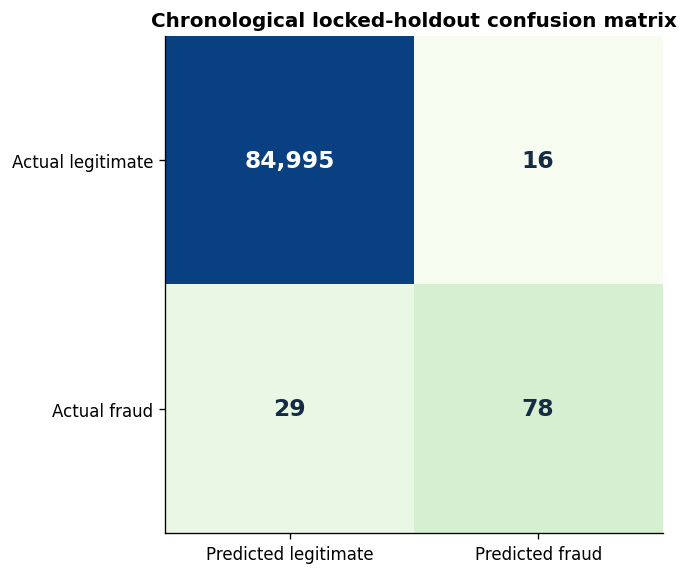

In [13]:
fig,ax=plt.subplots(figsize=(7,4.9))
cmat=np.array([[tn,fp],[fn,tp]])
ax.imshow(np.log10(cmat+1),cmap='GnBu')
for i in range(2):
 for j in range(2):
  ax.text(j,i,f'{cmat[i,j]:,}',ha='center',va='center',fontsize=14,fontweight='bold',
          color='white' if i==0 and j==0 else NAVY)
ax.set_xticks([0,1],['Predicted legitimate','Predicted fraud']);ax.set_yticks([0,1],['Actual legitimate','Actual fraud'])
ax.set_title('Chronological locked-holdout confusion matrix',fontweight='bold')
plot_done(fig)

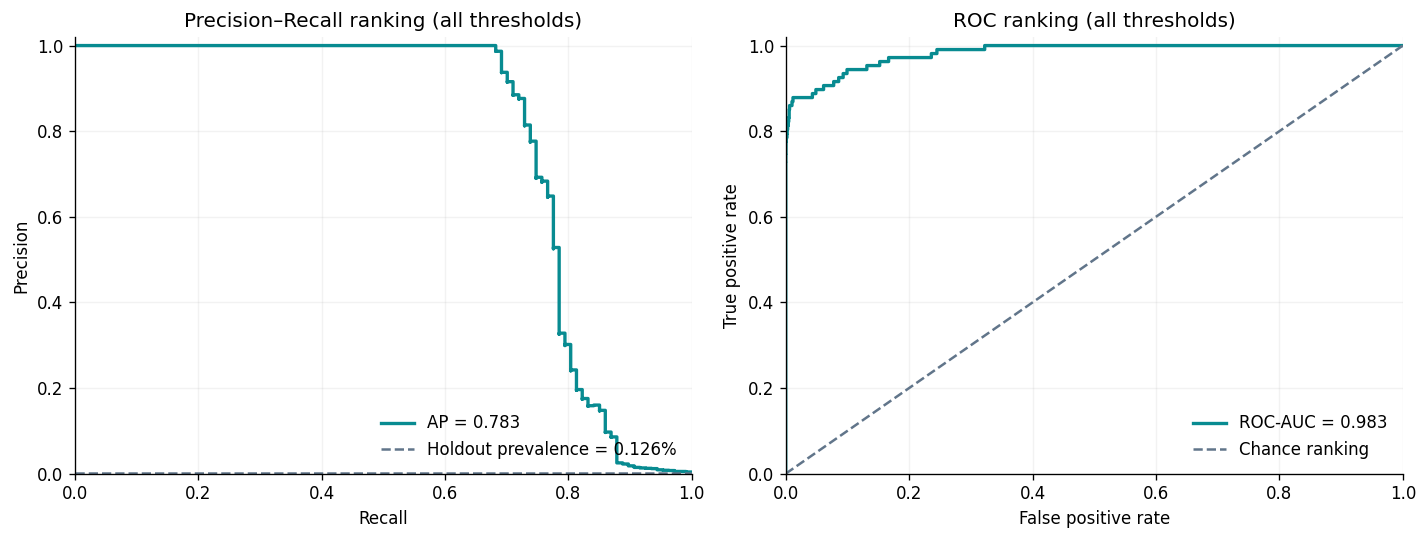

In [14]:
precision_points,recall_points,_=precision_recall_curve(y,s)
fpr,tpr,_=roc_curve(y,s)
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
axes[0].step(recall_points,precision_points,where='post',color=TEAL,lw=2,label=f'AP = {calculated["Average precision"]:.3f}')
axes[0].axhline(prevalence,ls='--',color=GREY,label=f'Holdout prevalence = {prevalence:.3%}')
axes[0].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall ranking (all thresholds)',xlim=(0,1),ylim=(0,1.02))
axes[1].plot(fpr,tpr,color=TEAL,lw=2,label=f'ROC-AUC = {calculated["ROC-AUC"]:.3f}')
axes[1].plot([0,1],[0,1],'--',color=GREY,label='Chance ranking')
axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC ranking (all thresholds)',xlim=(0,1),ylim=(0,1.02))
for ax in axes: ax.grid(alpha=.16);ax.legend(frameon=False,loc='lower right')
plot_done(fig)

#### Reported uncertainty: conditional on the trained model

The existing ML report records resampling-based intervals, **not** uncertainty from retraining the model, choosing a new threshold or future temporal drift. We report them descriptively and do not bootstrap anew to search for a more favorable result.

In [15]:
intervals=[]
for name,center,stem in [('Average precision',metric.pr_auc,'pr_auc'),('Precision',metric.precision,'precision'),
                         ('Case recall',metric.recall,'recall'),('Recorded fraud-value recall',metric.fraud_value_recall,'fraud_value_recall')]:
    low,high=f'{stem}_ci_low',f'{stem}_ci_high'
    if low in metric.index and high in metric.index:
        intervals.append({'Metric':name,'Estimate':center,'Lower bound':metric[low],'Upper bound':metric[high]})
interval_df=pd.DataFrame(intervals)
assert not interval_df.empty
show(interval_df,formats={'Estimate':'{:.2%}','Lower bound':'{:.2%}','Upper bound':'{:.2%}'})

,Metric,Estimate,Lower bound,Upper bound
0,Average precision,78.31%,70.42%,85.50%
1,Precision,82.98%,74.38%,90.22%
2,Case recall,72.90%,64.07%,80.67%
3,Recorded fraud-value recall,71.22%,51.40%,88.32%


### 10 · Actual transaction-level predictions and error investigation

The next displays contain **real saved holdout records**, sampled deterministically by outcome and transaction amount. Showing the largest recorded amount errors helps illustrate financial exposure, but an amount is **not** a verified bank loss. The saved `score` is a model output, not necessarily a calibrated probability. We do not infer merchant identity, geography or customer behavior from anonymized PCA values.

In [16]:
samples=[]
for outcome in ['TP','FN','FP','TN']:
    block=pred[pred.error_type.eq(outcome)].nlargest(3,'Amount').copy()
    block['Outcome']=outcome
    samples.append(block)
samples=pd.concat(samples,ignore_index=True)
show(samples[['Outcome','original_row','Time','Amount','Class','score','predicted_fraud']],
     formats={'Time':'{:,.0f}','Amount':'{:,.2f}','score':'{:.6f}'})
print('Selected by recorded Amount within each saved outcome class; not a random sample or a client case file.')

,Outcome,original_row,Time,Amount,Class,score,predicted_fraud
0,TP,249167,"154,278","1,504.93",1,0.994782,1
1,TP,199896,"133,184","1,335.00",1,0.993930,1
2,TP,233258,"147,501",996.27,1,0.896880,1
3,FN,249239,"154,309","1,096.99",1,0.021304,0
4,FN,215132,"139,951",723.21,1,0.625936,0
5,FN,275992,"166,831",634.30,1,0.422618,0
6,FP,274771,"166,198","25,691.16",0,0.932924,1
7,FP,213409,"139,246",913.52,0,0.828448,1
8,FP,216356,"140,440",804.00,0,0.767669,1
9,TN,284249,"172,273","10,199.44",0,0.006844,0


Selected by recorded Amount within each saved outcome class; not a random sample or a client case file.


,Outcome,Transactions,Recorded amount units
0,TP — detected fraud,78,"10,372.83"
1,FN — missed fraud,29,"4,192.16"
2,FP — false alert,16,"29,406.78"
3,TN — correct legitimate,"84,995","7,210,828.79"


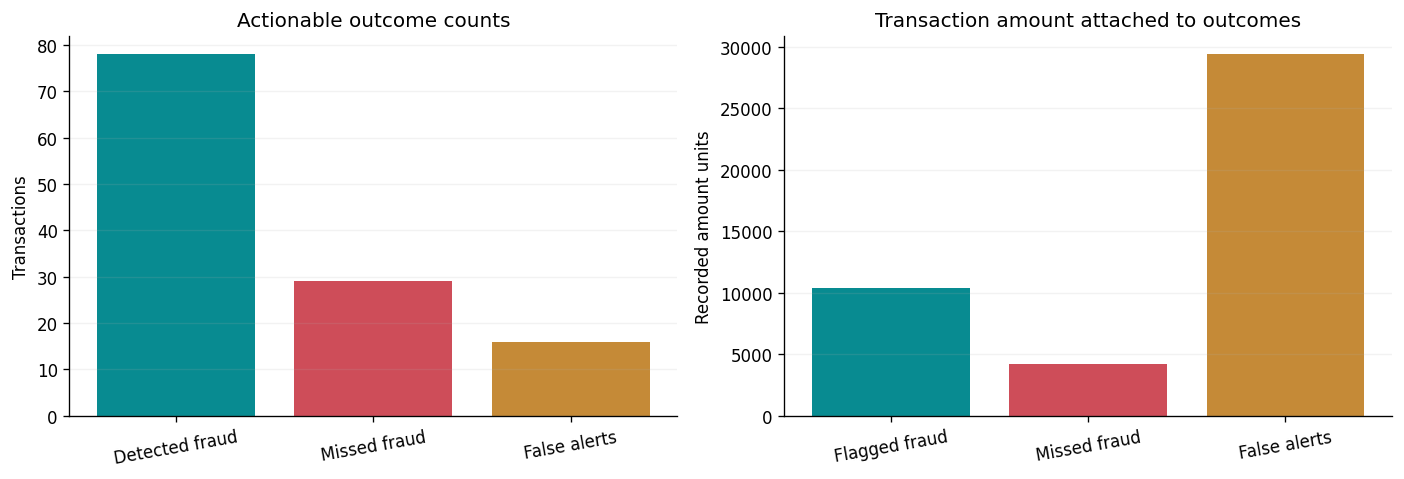

In [17]:
outcome_counts=pred.error_type.value_counts().reindex(['TP','FN','FP','TN'],fill_value=0)
outcome_amount=pred.groupby('error_type').Amount.sum().reindex(['TP','FN','FP','TN'],fill_value=0)
error_audit=pd.DataFrame({'Outcome':['TP — detected fraud','FN — missed fraud','FP — false alert','TN — correct legitimate'],
                          'Transactions':outcome_counts.to_numpy(),'Recorded amount units':outcome_amount.to_numpy()})
show(error_audit,formats={'Transactions':'{:,.0f}','Recorded amount units':'{:,.2f}'})
fig,axes=plt.subplots(1,2,figsize=(11.8,4.1))
axes[0].bar(['Detected fraud','Missed fraud','False alerts'],[tp,fn,fp],color=[TEAL,RED,GOLD]);axes[0].set_ylabel('Transactions');axes[0].set_title('Actionable outcome counts')
axes[1].bar(['Flagged fraud','Missed fraud','False alerts'],[flagged,missed,legitimate_flagged],color=[TEAL,RED,GOLD]);axes[1].set_ylabel('Recorded amount units');axes[1].set_title('Transaction amount attached to outcomes')
for ax in axes:ax.tick_params(axis='x',labelrotation=10);ax.grid(axis='y',alpha=.16)
plot_done(fig)

**Operational interpretation:** FP transactions are legitimate observations that would enter a *hypothetical review queue*. They were not necessarily blocked, and the recorded flagged amount does not establish customer harm. FN transactions are fraud labels not flagged at the training-selected threshold; their recorded amounts are not verified realized losses.

### 11 · Fraud-case recall versus recorded fraud-value recall

A model can catch many fraud cases without capturing the same share of recorded fraudulent transaction value. Here we measure both from the **same locked holdout predictions**, using the same threshold and same fraud-positive denominator.

,Measure,Captured,Missed,Share captured (%)
0,Fraud case recall,78.00,29.00,72.90%
1,Fraud value recall,"10,372.83","4,192.16",71.22%


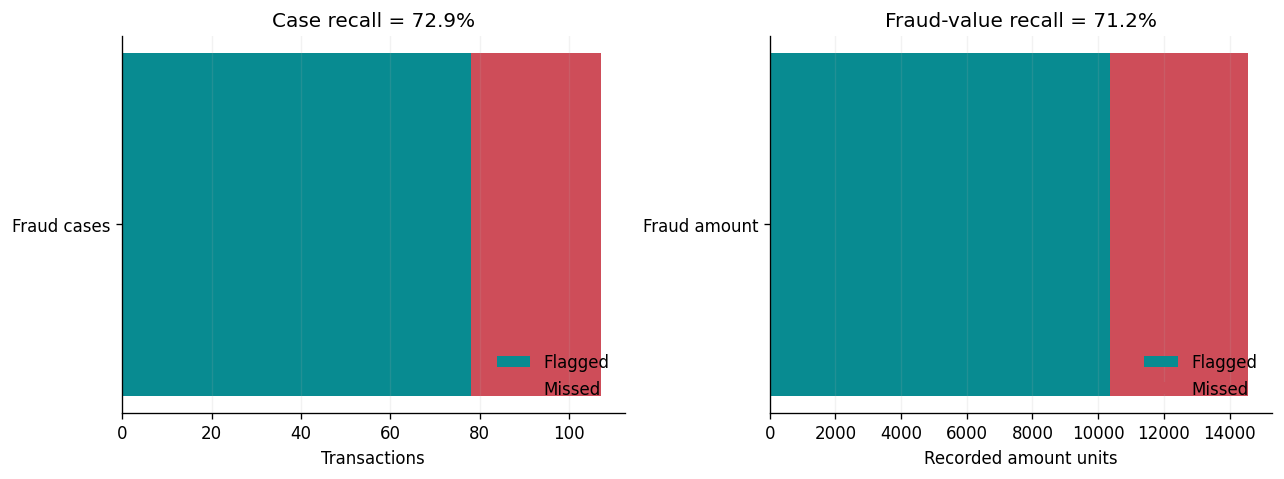

In [18]:
value_frame=pd.DataFrame([
 {'Measure':'Fraud case recall','Captured':tp,'Missed':fn,'Share captured (%)':100*tp/(tp+fn)},
 {'Measure':'Fraud value recall','Captured':flagged,'Missed':missed,'Share captured (%)':100*value_recall},
])
show(value_frame,formats={'Captured':'{:,.2f}','Missed':'{:,.2f}','Share captured (%)':'{:.2f}%'})
fig,axes=plt.subplots(1,2,figsize=(10.8,4.1))
axes[0].barh(['Fraud cases'],[tp],color=TEAL,label='Flagged');axes[0].barh(['Fraud cases'],[fn],left=[tp],color=RED,label='Missed')
axes[1].barh(['Fraud amount'],[flagged],color=TEAL,label='Flagged');axes[1].barh(['Fraud amount'],[missed],left=[flagged],color=RED,label='Missed')
axes[0].set(xlabel='Transactions',title=f'Case recall = {tp/(tp+fn):.1%}')
axes[1].set(xlabel='Recorded amount units',title=f'Fraud-value recall = {value_recall:.1%}')
for ax in axes:ax.legend(frameon=False,loc='lower right');ax.grid(axis='x',alpha=.16)
plot_done(fig)

## D · Reliability, evaluation sensitivity and research handoff
### 12 · Random versus chronological experiments — *descriptive*, not paired

A full random experiment is included **only if its actual nine-candidate metadata, CV table, metrics and predictions are present** in the project. A one-model smoke test is excluded. Because these experiments have different holdout populations and potentially different selected winners, their observed gaps do **not** isolate the causal effect of time and are not proof of future drift.

In [19]:
def headline(run_name):
    run_dir=ML/run_name
    m=load_csv(run_dir,'holdout_metrics.csv',{'split','selected_model','pr_auc','precision','recall','f1',
        'fraud_value_recall','tn','fp','fn','tp','test_fraud','threshold','test_rows'}).iloc[0]
    meta=json.loads((run_dir/'run_metadata.json').read_text(encoding='utf-8'))
    assert m.selected_model==meta['selected_model'] and np.isclose(m.threshold,meta['selected_threshold'],atol=1e-6)
    return {'Experiment':run_name,'Split':m['split'],'Selected model':m.selected_model,'Holdout rows':int(m.test_rows),
            'Fraud cases':int(m.test_fraud),'AP':m.pr_auc,'Precision':m.precision,'Case recall':m.recall,
            'F1':m.f1,'Value recall':m.fraud_value_recall,'Threshold':m.threshold}
rows=[headline(CHRONO)]
if RANDOM:rows.append(headline(RANDOM))
comparison=pd.DataFrame(rows)
show(comparison,formats={'Holdout rows':'{:,.0f}','AP':'{:.4f}','Precision':'{:.1%}',
                         'Case recall':'{:.1%}','F1':'{:.4f}','Value recall':'{:.1%}','Threshold':'{:.6f}'})
if not RANDOM:print('FULL random experiment is unavailable in this workspace. It will appear when its complete report folder is copied to reports/tables/ml/.')

,Experiment,Split,Selected model,Holdout rows,Fraud cases,AP,Precision,Case recall,F1,Value recall,Threshold
0,chronological_dedup_withTime_463fcded,chronological,XGBoost__SMOTE,"85,118",107,0.7831,83.0%,72.9%,0.7761,71.2%,0.715498
1,random_dedup_withTime_463fcded,random,XGBoost__class_weight,"85,118",142,0.8112,93.9%,75.4%,0.8359,78.1%,0.903320


#### Reliability is not the same as discrimination

We check the **Brier score** and produce a descriptive score-band audit from saved holdout predictions. It is a diagnostic, *not* a calibration fit. Brier loss can be low largely because fraud is rare. Do not use the test set to fit or choose a recalibrator. In particular, a score of 0.8 must **not** be treated as a verified 80% fraud probability.

In [20]:
edges=np.array([0,.001,.01,.05,.1,.2,.4,.6,.8,1.000001])
rbin=pred.assign(score_band=pd.cut(pred.score,bins=edges,include_lowest=True))
reliability=rbin.groupby('score_band',observed=True).agg(transactions=('Class','size'),observed_frauds=('Class','sum'),
                                mean_score=('score','mean'),observed_fraud_rate=('Class','mean')).reset_index()
show(reliability,formats={'transactions':'{:,.0f}','observed_frauds':'{:,.0f}',
                          'mean_score':'{:.4f}','observed_fraud_rate':'{:.2%}'})
print(f"Brier score: {metric.brier_score:.6f} | prevalence: {prevalence:.4%}. Descriptive bins only; no recalibration.")

,score_band,transactions,observed_frauds,mean_score,observed_fraud_rate
0,"(-0.001, 0.001]","71,944",4,0.0002,0.01%
1,"(0.001, 0.01]","10,965",9,0.0029,0.08%
2,"(0.01, 0.05]","1,687",5,0.0202,0.30%
3,"(0.05, 0.1]",209,3,0.0694,1.44%
4,"(0.1, 0.2]",119,2,0.1425,1.68%
5,"(0.2, 0.4]",73,2,0.2966,2.74%
6,"(0.4, 0.6]",22,3,0.4899,13.64%
7,"(0.6, 0.8]",8,1,0.6857,12.50%
8,"(0.8, 1.0]",91,78,0.9780,85.71%


Brier score: 0.000627 | prevalence: 0.1257%. Descriptive bins only; no recalibration.


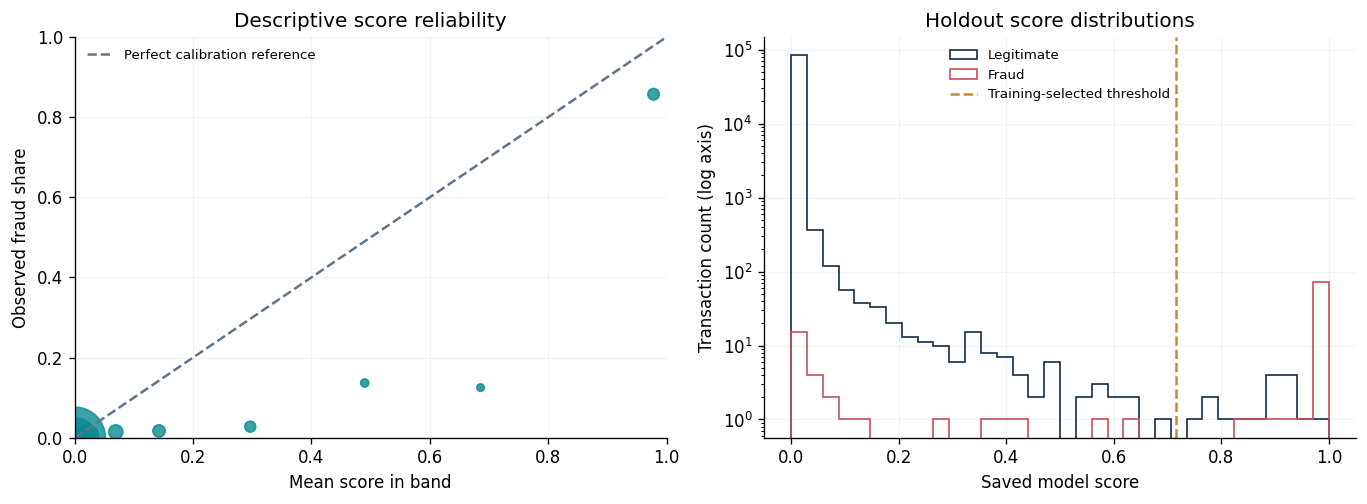

In [21]:
fig,axes=plt.subplots(1,2,figsize=(11.5,4.3))
axes[0].scatter(reliability.mean_score,reliability.observed_fraud_rate,
                s=np.maximum(20,np.sqrt(reliability.transactions)*5),alpha=.8,color=TEAL)
axes[0].plot([0,1],[0,1],'--',color=GREY,label='Perfect calibration reference')
axes[0].set(xlabel='Mean score in band',ylabel='Observed fraud share',title='Descriptive score reliability',xlim=(0,1),ylim=(0,1))
axes[0].legend(frameon=False,fontsize=8)
axes[1].hist(pred.loc[pred.Class.eq(0),'score'],bins=np.linspace(0,1,35),histtype='step',color=NAVY,label='Legitimate')
axes[1].hist(pred.loc[pred.Class.eq(1),'score'],bins=np.linspace(0,1,35),histtype='step',color=RED,label='Fraud')
axes[1].axvline(cm['selected_threshold'],ls='--',color=GOLD,label='Training-selected threshold')
axes[1].set(xlabel='Saved model score',ylabel='Transaction count (log axis)',title='Holdout score distributions')
axes[1].set_yscale('log');axes[1].legend(frameon=False,fontsize=8)
for ax in axes:ax.grid(alpha=.14)
plot_done(fig)

#### Temporal variation in the historical holdout

The dataset covers roughly two days; within-holdout variability does **not** establish recurring daily patterns or production drift. We group the chronological holdout in **equal-count, transaction-order segments** so that each segment contains broadly similar volume. Any segment with no labeled fraud must have undefined recall, not an invented zero recall.

,segment,transactions,frauds,flagged,TP,case_recall,fraud_rate
0,S1,"10,640",10,11,9,90.0%,0.094%
1,S2,"10,640",12,8,5,41.7%,0.113%
2,S3,"10,639",15,13,12,80.0%,0.141%
3,S4,"10,640",18,14,14,77.8%,0.169%
4,S5,"10,640",25,21,19,76.0%,0.235%
5,S6,"10,639",14,12,11,78.6%,0.132%
6,S7,"10,640",3,6,2,66.7%,0.028%
7,S8,"10,640",10,9,6,60.0%,0.094%


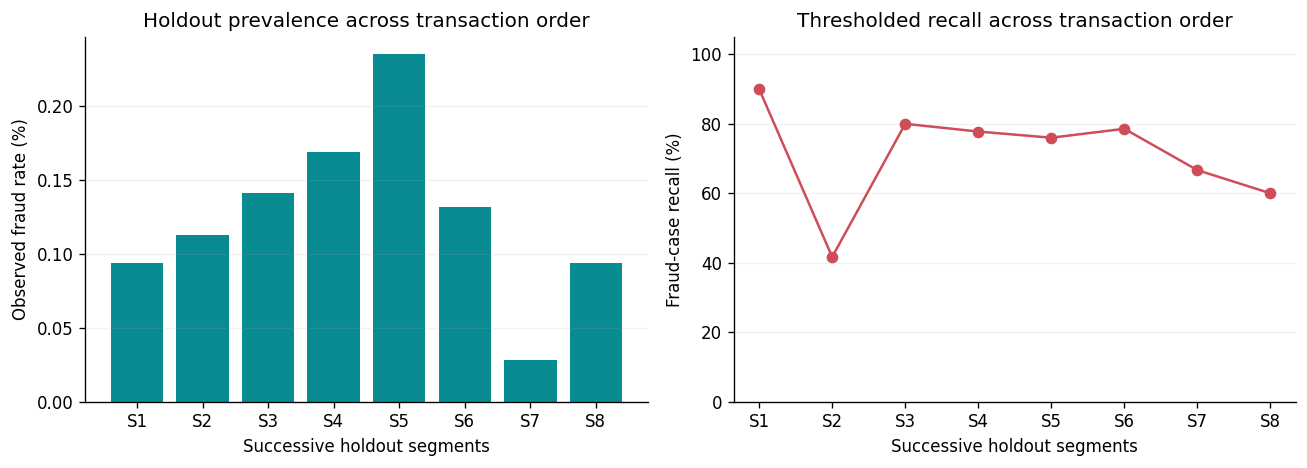

In [22]:
ordered=pred.sort_values(['Time','original_row']).reset_index(drop=True).copy()
ordered['segment']=pd.qcut(np.arange(len(ordered)),q=8,labels=[f'S{i}' for i in range(1,9)])
segment=ordered.groupby('segment',observed=True).agg(transactions=('Class','size'),frauds=('Class','sum'),
                                                     flagged=('predicted_fraud','sum')).reset_index()
segment['TP']=[int(((ordered.segment==r.segment)&ordered.error_type.eq('TP')).sum()) for r in segment.itertuples()]
segment['case_recall']=np.where(segment.frauds>0,segment.TP/segment.frauds,np.nan)
segment['fraud_rate']=segment.frauds/segment.transactions
show(segment,formats={'transactions':'{:,.0f}','fraud_rate':'{:.3%}','case_recall':'{:.1%}'})
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(segment.segment.astype(str),segment.fraud_rate*100,color=TEAL)
axes[0].set(xlabel='Successive holdout segments',ylabel='Observed fraud rate (%)',title='Holdout prevalence across transaction order')
axes[1].plot(segment.segment.astype(str),segment.case_recall*100,marker='o',color=RED)
axes[1].set(xlabel='Successive holdout segments',ylabel='Fraud-case recall (%)',title='Thresholded recall across transaction order',ylim=(0,105))
for ax in axes:ax.grid(axis='y',alpha=.16)
plot_done(fig)

### Optional · Direct inference with a trusted saved model

**Core prediction reproduction above is complete without a model file.** A direct `joblib.load` is *intentionally not executed automatically* because loading serialized Python objects can run code, requires a compatible library environment, and requires reconstructing the identical raw-feature split in exactly the original order. If you later run an inference audit, only load the model artifact **produced by your own trusted pipeline**, verify its metadata/source fingerprint and ensure identical preprocessing and feature order. Never substitute another dataset, invent transactions, or update the trained pipeline during this notebook.

In [23]:
from pathlib import Path
model_dir=ROOT/'models'
model_files=sorted(model_dir.rglob('*.joblib')) if model_dir.is_dir() else []
print('Serialized model files found (not loaded or executed):',len(model_files))
for p in model_files[:8]:print(' •',p.relative_to(ROOT))
print('Verified real predictions and classification are reproduced above without refitting any model.')

Serialized model files found (not loaded or executed): 3
 • models\best_model_chronological_dedup_withTime_463fcded.joblib
 • models\best_model_random_dedup_withTime_463fcded.joblib
 • models\best_model_random_dedup_withTime_ee769471.joblib
Verified real predictions and classification are reproduced above without refitting any model.


### 13 · Findings, limitations and decision handoff

The evaluation is credible only if each statement is accompanied by its evidence and scope. None of the following constitutes a deployment guarantee, customer-friction estimate, or verified prevented loss.

In [24]:
register=pd.DataFrame([
 ('Candidate search','Nine candidate configurations; winner selected by pooled training OOF AP',
  'Chosen configuration within this search grid','Best possible architecture or future performance'),
 ('Threshold provenance','Training OOF F1 selected threshold','A fixed historical classification operating point','Optimized threshold for production costs'),
 ('Held-out detection',f'{tp} TP, {fp} FP, {fn} FN, {tn:,} TN','Historical case detection and alert burden','Real blocking decisions or deployed recall'),
 ('Ranking quality',f'AP {metric.pr_auc:.3f}; holdout prevalence {prevalence:.3%}',
  'Useful ranking on the given holdout','A calibrated fraud probability'),
 ('Recorded value',f'{flagged:,.2f} flagged vs {missed:,.2f} missed amount units',
  'Historical fraudulent transaction amount covered','Actual financial savings'),
 ('Generalization','Chronological holdout and conditional bootstrap intervals',
  'One time-ordered evaluation of the fitted model','Long-run robustness or absence of concept drift'),
],columns=['Evidence domain','Saved evidence','Supported reading','Not demonstrated'])
show(register)

,Evidence domain,Saved evidence,Supported reading,Not demonstrated
0,Candidate search,Nine candidate configurations; winner selected by pooled training OOF AP,Chosen configuration within this search grid,Best possible architecture or future performance
1,Threshold provenance,Training OOF F1 selected threshold,A fixed historical classification operating point,Optimized threshold for production costs
2,Held-out detection,"78 TP, 16 FP, 29 FN, 84,995 TN",Historical case detection and alert burden,Real blocking decisions or deployed recall
3,Ranking quality,AP 0.783; holdout prevalence 0.126%,Useful ranking on the given holdout,A calibrated fraud probability
4,Recorded value,"10,372.83 flagged vs 4,192.16 missed amount units",Historical fraudulent transaction amount covered,Actual financial savings
5,Generalization,Chronological holdout and conditional bootstrap intervals,One time-ordered evaluation of the fitted model,Long-run robustness or absence of concept drift


## Final audit · Reproducibility and methodological boundaries

**This notebook passes only if:** its primary run is a full nine-candidate chronological experiment; all transaction predictions have valid scores and match the fixed training threshold; all four confusion counts and six reported predictive metrics are independently reproduced; recorded fraud amount totals and value recall match; and no file was altered.

**What we did not do:** retrain, apply SMOTE to test data, select a winner from holdout performance, optimize a threshold or review policy on holdout labels, calibrate on test outcomes, generate fictitious credit-card features, or claim actual prevented losses.

**Handoff to Notebook 04:** The model yields fraud **scores**; a bank investigation team has finite review capacity. Notebook 04 therefore compares *training-selected ranking policies* under fixed batch-review budgets, using the same historical holdout but with an entirely different **decision objective** from thresholded classification.

In [25]:
assert len(cv)==9 and len(fold)==27
assert cm['selected_model']==cv.key.iloc[0]
assert len(pred)==cm['test_rows']==int(metric.test_rows)
assert (pred.predicted_fraud.to_numpy()==(pred.score.to_numpy()>=cm['selected_threshold']).astype(int)).all()
assert tp+fp+fn+tn==len(pred)
assert int(pred.Class.sum())==int(metric.test_fraud)
assert np.isclose(flagged+missed,fraud_total,atol=.01)
assert np.isclose(flagged/fraud_total,metric.fraud_value_recall,atol=1e-7)
for k,val in calculated.items():assert np.isclose(val,metric[fields[k]],atol=1e-7)
print('AUDIT PASSED')
print('Nine training candidates:',len(cv),'| Chronological OOF folds:',len(selected_folds))
print('Real holdout predictions:',f'{len(pred):,}','| confusion: TP',tp,'FP',fp,'FN',fn,'TN',tn)
print('AP:',f'{calculated["Average precision"]:.4f}','| Case recall:',f'{calculated["Recall"]:.2%}',
      '| Recorded fraud-value recall:',f'{value_recall:.2%}')
print('Full random comparison:', 'INCLUDED' if RANDOM else 'SKIPPED: full random report not present')
print('No model training, threshold change, report mutation or test-set policy selection.')

AUDIT PASSED
Nine training candidates: 9 | Chronological OOF folds: 3
Real holdout predictions: 85,118 | confusion: TP 78 FP 16 FN 29 TN 84995
AP: 0.7831 | Case recall: 72.90% | Recorded fraud-value recall: 71.22%
Full random comparison: INCLUDED
No model training, threshold change, report mutation or test-set policy selection.
